# Surge Pricing Strategy for a Rideshare Company using Reinforcement Learning

**Module Project Notebook / Repo-ready version**  
**Dataset:** Uber & Lyft Cab Prices (Kaggle)  
**Goal:** Learn a surge pricing policy that maximizes expected total reward.

---

## What this notebook covers

This notebook is designed to be run **top to bottom** and includes everything needed for the project:

1. Data loading and cleaning  
2. Weather merge and feature engineering  
3. Construction of an RL environment from historical data  
4. A **base-price model** and a **demand-proxy model**  
5. A reward function for surge pricing  
6. Two RL algorithms:
   - **Tabular Q-Learning**
   - **Fitted Q-Iteration (FQI)**  
7. Baselines:
   - No surge
   - Fixed surge
   - Simple heuristic policy  
8. Evaluation and visualisations  
9. Export of report-ready tables and figures

---

## Important modelling note

This dataset contains **historical price quotes** from Uber/Lyft APIs, not realized trip completions.  
So this notebook uses a **latent demand proxy** rather than true observed demand. That assumption should be stated clearly in the report.

---

## Folder structure expected

Place the Kaggle files in:

```text
./data/cab_rides.csv
./data/weather.csv
```

Outputs from this notebook will be written to:

```text
./outputs/
```


> This version is intended to **replace or extend** the partial `RL_SurgePricing.ipynb` already in your GitHub repo.


## Methodology summary

We model surge pricing as a Markov Decision Process (MDP):

- **State**: time, route, cab type, weather, distance, and model-based demand/base-fare signals  
- **Action**: surge multiplier from **1.0** to **2.0** in increments of **0.1**  
- **Reward**: expected revenue under the chosen surge factor minus a penalty for aggressive pricing  
- **Transition**: move to the next chronological market context in the historical data

### Why a demand proxy is needed
The dataset does not contain realized booking counts or driver supply.  
To satisfy the project brief, we construct a **continuous demand proxy** from historical market tightness:

- higher historical average surge suggests stronger market pressure
- observation count within a time-route-product context gives a weak additional signal

This proxy is then predicted from context features using supervised learning and used inside the RL environment.


In [25]:
# Core imports and project configuration

from pathlib import Path
import warnings
import math
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
import importlib
import surge_pricing_utils
importlib.reload(surge_pricing_utils)
from surge_pricing_utils import (
    set_global_seed,
    normalize_columns,
    parse_timestamp_column,
    load_raw_data,
    merge_weather,
    clean_rides,
    build_context_table,
    time_based_split,
    get_feature_columns,
    build_preprocessor,
    build_regression_pipeline,
    regression_metrics,
    RewardModel,
    make_state_builder,
    TabularQAgent,
    FittedQIterationAgent,
    TabularSARSAAgent,
    GaussianThompsonSamplingAgent,
    evaluate_policy,
    summarize_policy_results,
    fixed_policy,
    simple_peak_weather_policy,
)
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.utils.parallel")

SEED = 42

def find_data_dir() -> Path:
    candidates = [
        Path("./data"),
        Path("../data"),
        Path("../../data"),
        Path("."),
    ]
    for candidate in candidates:
        if (candidate / "cab_rides.csv").exists() or (candidate / "rideshare_kaggle.csv").exists():
            return candidate
    return Path("./data")

DATA_DIR = find_data_dir()
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Set to True for faster experimentation on a smaller subset.
USE_DEV_SAMPLE = False
DEV_SAMPLE_FRAC = 0.25

ACTION_SPACE = np.round(np.arange(1.0, 2.01, 0.1), 2)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

print("Using DATA_DIR:", DATA_DIR.resolve())
print("Using OUTPUT_DIR:", OUTPUT_DIR.resolve())


Using DATA_DIR: C:\Users\spide\Documents\GitHub\CA2-H9AIDM\data
Using OUTPUT_DIR: C:\Users\spide\Documents\GitHub\CA2-H9AIDM\notebooks\outputs


## Helper functions and RL classes

This cell defines all utility functions used throughout the notebook, including:

- data loading and weather merge
- context aggregation
- supervised model pipelines
- reward model
- tabular Q-learning
- fitted Q-iteration
- policy evaluation helpers


In [26]:
# Reproducibility

set_global_seed(SEED)
sns.set_theme(style="whitegrid" )
print("Random seed set to:", SEED)
print("Action space:", ACTION_SPACE)


Random seed set to: 42
Action space: [1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2. ]


## 1. Load raw data


In [27]:
cab_raw, weather_raw = load_raw_data(DATA_DIR)

print("Cab data shape:", cab_raw.shape)
display(cab_raw.head())

if weather_raw is not None:
    print("Weather data shape:", weather_raw.shape)
    display(weather_raw.head())
else:
    print("No weather file detected. The notebook will continue with ride-only features.")


Cab data shape: (693071, 10)


,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name
0,0.44,Lyft,1544952607890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared
1,0.44,Lyft,1543284023677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux
2,0.44,Lyft,1543366822198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft
3,0.44,Lyft,1543553582749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL
4,0.44,Lyft,1543463360223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL


Weather data shape: (6276, 8)


,temp,location,clouds,pressure,rain,time_stamp,humidity,wind
0,42.42,Back Bay,1.0,1012.14,0.1228,1545003901,0.77,11.25
1,42.43,Beacon Hill,1.0,1012.15,0.1846,1545003901,0.76,11.32
2,42.50,Boston University,1.0,1012.15,0.1089,1545003901,0.76,11.07
3,42.11,Fenway,1.0,1012.13,0.0969,1545003901,0.77,11.09
4,43.13,Financial District,1.0,1012.14,0.1786,1545003901,0.75,11.49


In [28]:
# Optional development sampling for faster iteration

if USE_DEV_SAMPLE:
    cab_raw = cab_raw.sample(frac=DEV_SAMPLE_FRAC, random_state=SEED).sort_index().reset_index(drop=True)
    print(f"Using development sample with {len(cab_raw):,} rows ({DEV_SAMPLE_FRAC:.0%} of the ride data).")
else:
    print("Using full dataset.")


Using full dataset.


## 2. Merge weather data, clean rides, and create market contexts

We first:

1. parse timestamps  
2. merge weather at the hourly level  
3. clean missing/invalid rows  
4. aggregate rows into **chronological market contexts**

A context is defined by:

- hour
- source
- destination
- cab type
- product name


In [29]:
merged_df = merge_weather(cab_raw, weather_raw)
rides_df = clean_rides(merged_df)
context_df = build_context_table(rides_df)

print("Merged data shape after cleaning:", merged_df.shape)
print("Merged ride-level data shape:", rides_df.shape)
print("Context-level data shape:", context_df.shape)
display(context_df.head())


Merged data shape after cleaning: (693071, 19)
Merged ride-level data shape: (637976, 25)
Context-level data shape: (246992, 26)


,time_hour,source,destination,cab_type,name,distance_mean,price_mean,price_median,surge_mean,surge_max,surge_share,obs_count,temp,clouds,pressure,rain,humidity,wind,route,hour,weekday,is_weekend,day,month,base_price_target,demand_proxy_target
0,2018-11-26 03:00:00,Back Bay,Fenway,Lyft,Lux,1.66,26.0,26.0,1.75,1.75,1.0,1,41.04,0.87,1014.39,0.0118,0.92,1.46,Back Bay -> Fenway,3,0,0,26,11,14.857143,0.3
1,2018-11-26 03:00:00,South Station,Beacon Hill,Uber,UberX,2.50,10.5,10.5,1.00,1.00,0.0,1,40.86,0.87,1014.39,0.0118,0.93,1.60,South Station -> Beacon Hill,3,0,0,26,11,10.500000,0.0
2,2018-11-26 03:00:00,South Station,Beacon Hill,Uber,Black SUV,2.50,28.5,28.5,1.00,1.00,0.0,1,40.86,0.87,1014.39,0.0118,0.93,1.60,South Station -> Beacon Hill,3,0,0,26,11,28.500000,0.0
3,2018-11-26 03:00:00,South Station,Back Bay,Uber,UberXL,3.44,21.5,21.5,1.00,1.00,0.0,1,40.86,0.87,1014.39,0.0118,0.93,1.60,South Station -> Back Bay,3,0,0,26,11,21.500000,0.0
4,2018-11-26 03:00:00,South Station,Back Bay,Uber,Black SUV,3.44,35.0,35.0,1.00,1.00,0.0,1,40.86,0.87,1014.39,0.0118,0.93,1.60,South Station -> Back Bay,3,0,0,26,11,35.000000,0.0


In [30]:
# Save the processed context table for later reuse if desired
context_df.to_csv(OUTPUT_DIR / "context_table.csv", index=False)
print("Saved context table to:", OUTPUT_DIR / "context_table.csv")


Saved context table to: outputs\context_table.csv


## 3. Basic exploratory analysis


In [31]:
# Missing values overview for the context table

missing_summary = (
    context_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)
display(missing_summary.head(26))


,missing_count
time_hour,0
source,0
destination,0
cab_type,0
name,0
distance_mean,0
price_mean,0
price_median,0
surge_mean,0
surge_max,0


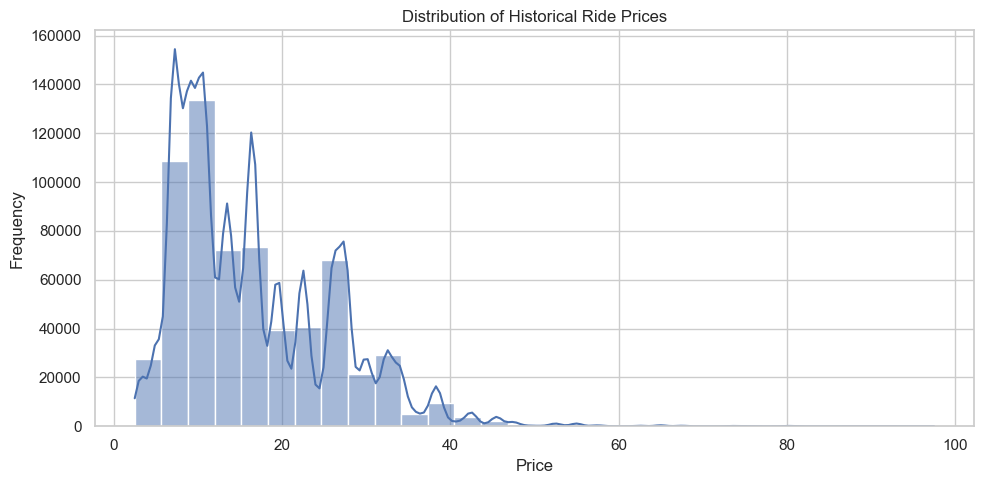

In [32]:
# Historical distribution of ride prices

plt.figure(figsize=(10, 5))
sns.histplot(rides_df["price"].dropna(), bins=30, kde=True)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Historical Ride Prices")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_distribution.png", bbox_inches="tight")
plt.show()

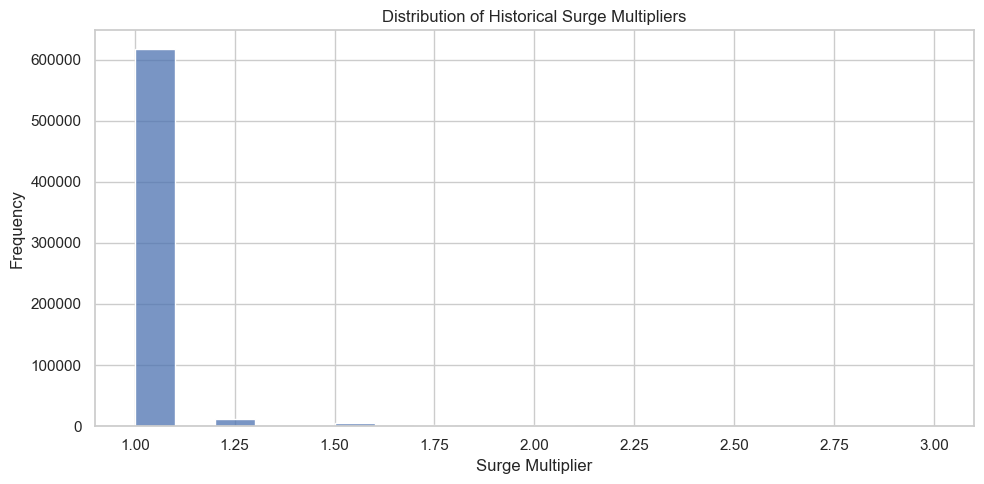

In [33]:
# Historical distribution of surge multipliers

plt.figure(figsize=(10, 5))
sns.histplot(rides_df["surge_multiplier"].dropna(), bins=20, kde=False)
plt.xlabel("Surge Multiplier")
plt.ylabel("Frequency")
plt.title("Distribution of Historical Surge Multipliers")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "surge_multiplier_distribution.png", bbox_inches="tight")
plt.show()

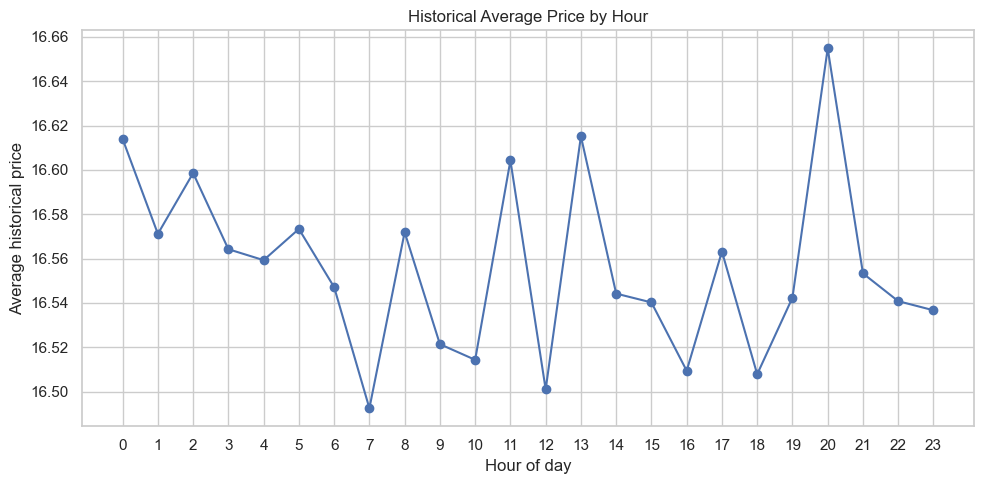

In [34]:
# Historical average price by hour

hourly = (
    context_df.groupby("hour", as_index=False)
    .agg(
        avg_price=("price_mean", "mean"),
        avg_surge=("surge_mean", "mean")
    )
)

plt.figure(figsize=(10, 5))
plt.plot(hourly["hour"], hourly["avg_price"], marker="o", label="Average Price")
plt.xlabel("Hour of day")
plt.ylabel("Average historical price")
plt.title("Historical Average Price by Hour")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "historical_price_surge_by_hour.png", bbox_inches="tight")
plt.show()


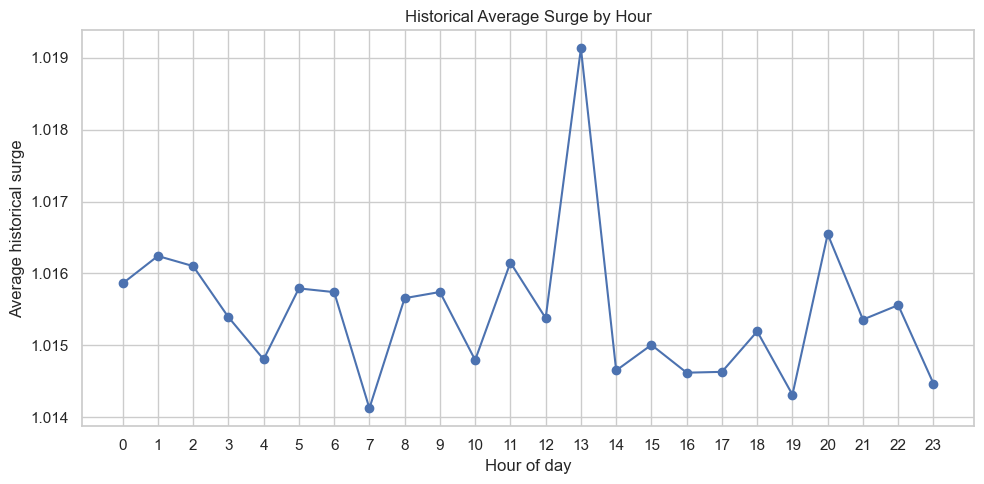

In [35]:
# Historical average surge by hour
plt.figure(figsize=(10, 5))
plt.plot(hourly["hour"], hourly["avg_surge"], marker="o", label="Average Surge")
plt.xlabel("Hour of day")
plt.ylabel("Average historical surge")
plt.title("Historical Average Surge by Hour")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "historical_surge_by_hour.png", bbox_inches="tight")
plt.show()

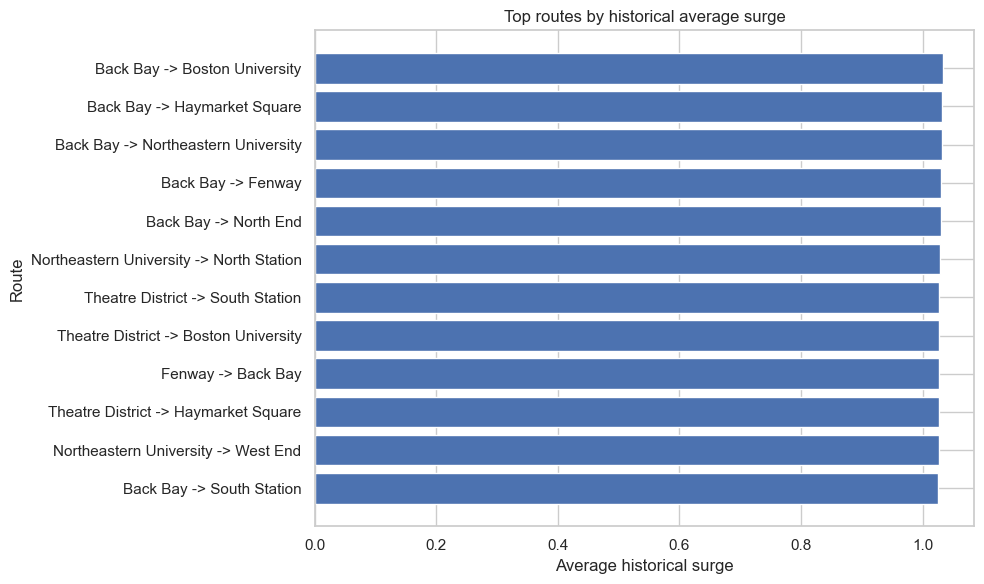

,route,avg_surge,avg_price,n
0,Back Bay -> Boston University,1.033041,14.037558,3408
2,Back Bay -> Haymarket Square,1.032193,18.020216,3428
4,Back Bay -> Northeastern University,1.031589,13.135332,3421
1,Back Bay -> Fenway,1.031115,13.732817,3391
3,Back Bay -> North End,1.030184,19.511176,3470
51,Northeastern University -> North Station,1.028471,20.001387,3417
65,Theatre District -> South Station,1.027861,12.888871,3425
60,Theatre District -> Boston University,1.027532,20.530207,3480
18,Fenway -> Back Bay,1.027303,13.881804,3416
62,Theatre District -> Haymarket Square,1.026960,15.317611,3422


In [36]:
# Top routes by average historical surge

top_routes = (
    context_df.groupby("route", as_index=False)
    .agg(avg_surge=("surge_mean", "mean"), avg_price=("price_mean", "mean"), n=("route", "size"))
    .sort_values("avg_surge", ascending=False)
    .head(12)
)

plt.figure(figsize=(10, 6))
plt.barh(top_routes["route"][::-1], top_routes["avg_surge"][::-1])
plt.xlabel("Average historical surge")
plt.ylabel("Route")
plt.title("Top routes by historical average surge")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_routes_by_historical_surge.png", bbox_inches="tight")
plt.show()

display(top_routes)


## 4. Train / validation / test split

We use a **time-based split** rather than random shuffling to avoid leakage:

- Train: first 70%
- Validation: next 15%
- Test: final 15%


In [37]:
train_df, val_df, test_df = time_based_split(context_df, train_frac=0.70, val_frac=0.15)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTime ranges")
print("Train:", train_df["time_hour"].min(), "to", train_df["time_hour"].max())
print("Validation:", val_df["time_hour"].min(), "to", val_df["time_hour"].max())
print("Test:", test_df["time_hour"].min(), "to", test_df["time_hour"].max())


Train shape: (172699, 26)
Validation shape: (37332, 26)
Test shape: (36961, 26)

Time ranges
Train: 2018-11-26 03:00:00 to 2018-12-14 15:00:00
Validation: 2018-12-14 16:00:00 to 2018-12-16 17:00:00
Test: 2018-12-16 18:00:00 to 2018-12-18 19:00:00


In [38]:
#Target summaries
context_df[["base_price_target", "demand_proxy_target", "surge_mean", "obs_count"]].describe()

,base_price_target,demand_proxy_target,surge_mean,obs_count
count,246992.000000,246992.000000,246992.000000,246992.000000
mean,16.259503,0.099145,1.015465,2.582982
std,8.796194,0.080971,0.073690,1.594792
min,2.500000,0.000000,1.000000,1.000000
25%,9.000000,0.000000,1.000000,1.000000
50%,13.500000,0.075786,1.000000,2.000000
75%,22.500000,0.162890,1.000000,3.000000
max,71.000000,0.675786,2.500000,16.000000


In [39]:
#Check for any leakage in split
print(train_df["time_hour"].max() < val_df["time_hour"].min())
print(val_df["time_hour"].max() < test_df["time_hour"].min())

True
True


## 5. Supervised models

We build two models from the contextual features:

1. **Base-price model**  
   Predicts the non-surge fare component.

2. **Demand-proxy model**  
   Predicts the latent market-pressure score in `[0, 1]`.

These predictions become part of the RL state and reward calculation.


In [40]:
categorical_cols, numeric_cols = get_feature_columns(context_df)
feature_cols = categorical_cols + numeric_cols

print("Categorical features:", categorical_cols)
print("Numeric features:", numeric_cols)
print("Total feature count before one-hot encoding:", len(feature_cols))


Categorical features: ['source', 'destination', 'cab_type', 'name']
Numeric features: ['distance_mean', 'hour', 'weekday', 'is_weekend', 'day', 'month', 'temp', 'clouds', 'pressure', 'rain', 'humidity', 'wind']
Total feature count before one-hot encoding: 16


In [41]:
# Build and fit the supervised models

base_price_model = build_regression_pipeline(
    categorical_cols,
    numeric_cols,
    model=RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=1,
        verbose=0
    )
)

demand_model = build_regression_pipeline(
    categorical_cols,
    numeric_cols,
    model=RandomForestRegressor(
        n_estimators=300,
        max_depth=18,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=1,
        verbose=0
    )
)

pbar = tqdm(total=2, desc="Training supervised models")
try:
    base_price_model.fit(train_df[feature_cols], train_df["base_price_target"])
    pbar.update(1)

    demand_model.fit(train_df[feature_cols], train_df["demand_proxy_target"])
    pbar.update(1)
finally:
    pbar.close()

splits = {
    "train": train_df.copy(),
    "validation": val_df.copy(),
    "test": test_df.copy(),
}

for split_name, split_data in tqdm(splits.items(), total=len(splits), desc="Generating predictions"):
    split_data["pred_base_price"] = base_price_model.predict(split_data[feature_cols])
    split_data["pred_demand_score"] = np.clip(
        demand_model.predict(split_data[feature_cols]),
        0.0,
        1.0
    )
    splits[split_name] = split_data

train_df = splits["train"]
val_df = splits["validation"]
test_df = splits["test"]

print("Finished fitting supervised models and generating predictions.")


Training supervised models:   0%|          | 0/2 [00:00<?, ?it/s]

Generating predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Finished fitting supervised models and generating predictions.


In [42]:
# Evaluate supervised models on validation and test sets

metric_rows = []

for split_name, split_data in [("validation", val_df), ("test", test_df)]:
    base_metrics = regression_metrics(split_data["base_price_target"], split_data["pred_base_price"])
    demand_metrics = regression_metrics(split_data["demand_proxy_target"], split_data["pred_demand_score"])

    metric_rows.append({
        "split": split_name,
        "model": "Base Price Model",
        **base_metrics
    })
    metric_rows.append({
        "split": split_name,
        "model": "Demand Proxy Model",
        **demand_metrics
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)

metrics_df.to_csv(OUTPUT_DIR / "supervised_model_metrics.csv", index=False)


,split,model,RMSE,MAE,R2
0,validation,Base Price Model,1.279204,0.813638,0.978906
1,validation,Demand Proxy Model,0.069476,0.055893,0.105768
2,test,Base Price Model,1.287484,0.836337,0.978725
3,test,Demand Proxy Model,0.073802,0.060044,0.007181


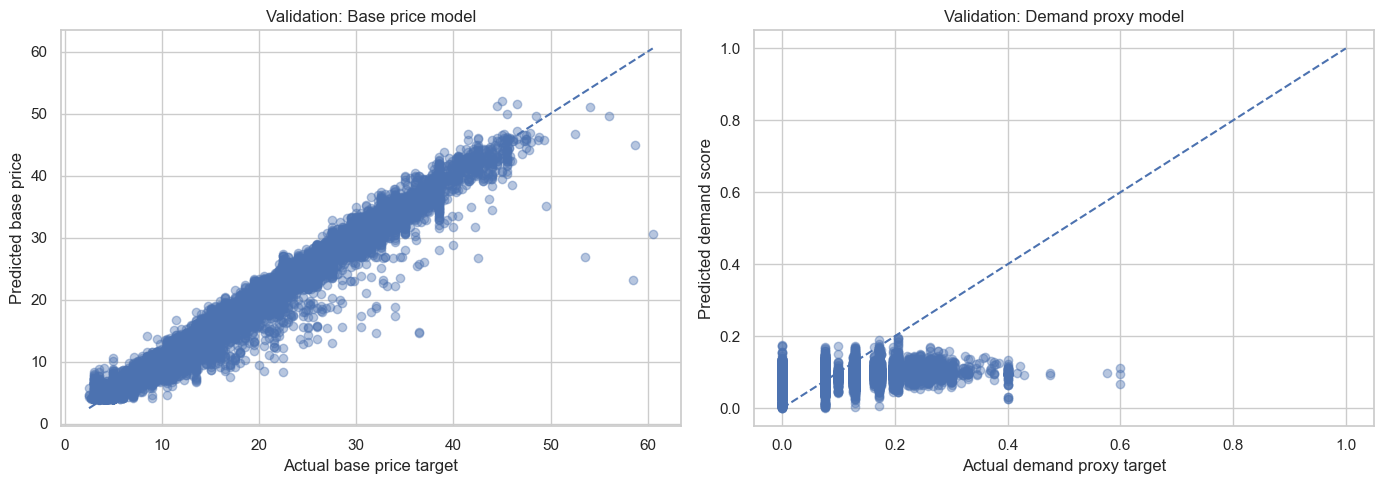

In [43]:
# Predicted vs actual diagnostic plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(val_df["base_price_target"], val_df["pred_base_price"], alpha=0.4)
axes[0].plot(
    [val_df["base_price_target"].min(), val_df["base_price_target"].max()],
    [val_df["base_price_target"].min(), val_df["base_price_target"].max()],
    linestyle="--"
)
axes[0].set_title("Validation: Base price model")
axes[0].set_xlabel("Actual base price target")
axes[0].set_ylabel("Predicted base price")

axes[1].scatter(val_df["demand_proxy_target"], val_df["pred_demand_score"], alpha=0.4)
axes[1].plot([0, 1], [0, 1], linestyle="--")
axes[1].set_title("Validation: Demand proxy model")
axes[1].set_xlabel("Actual demand proxy target")
axes[1].set_ylabel("Predicted demand score")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "supervised_model_diagnostics.png", bbox_inches="tight")
plt.show()


## 6. Reward model

The reward model is designed to capture the main trade-off in surge pricing:

- higher surge factor increases revenue per ride
- but it reduces demand conversion, especially in low-demand contexts
- extreme surges are penalized

### Key design idea
We make the **price sensitivity depend on the predicted demand score**.

That means:

- in **low-demand** states, customers are very sensitive to higher prices
- in **high-demand** states, the platform can tolerate stronger surge


In [44]:
reward_model = RewardModel(
    elasticity_base=1.20,
    elasticity_slope=0.90,
    min_elasticity=0.15,
    penalty_weight=0.10,
    demand_scale=4.0,
    min_demand_units=0.5,
)

reward_model


RewardModel(elasticity_base=1.2, elasticity_slope=0.9, min_elasticity=0.15, penalty_weight=0.1, demand_scale=4.0, min_demand_units=0.5)

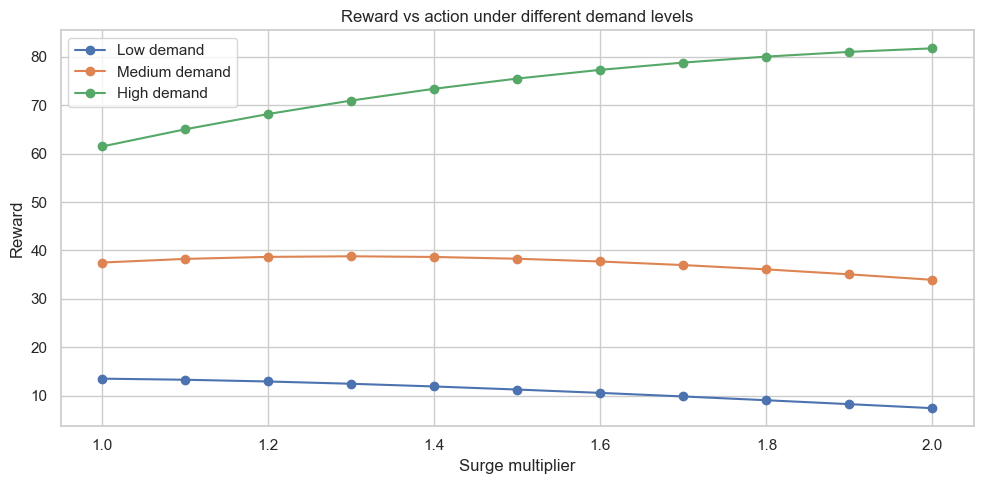

In [45]:
# Visualise how the reward changes with action for low, medium, and high demand contexts

base_price_example = 15.0
demand_levels = [0.1, 0.5, 0.9]
labels = ["Low demand", "Medium demand", "High demand"]

plt.figure(figsize=(10, 5))
for demand, label in zip(demand_levels, labels):
    rewards = reward_model.reward(
        base_price=np.full_like(ACTION_SPACE, base_price_example, dtype=float),
        demand_score=np.full_like(ACTION_SPACE, demand, dtype=float),
        action=ACTION_SPACE
    )
    plt.plot(ACTION_SPACE, rewards, marker="o", label=label)

plt.xlabel("Surge multiplier")
plt.ylabel("Reward")
plt.title("Reward vs action under different demand levels")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "reward_vs_action.png", bbox_inches="tight")
plt.show()


## 7. Tabular Q-Learning

For tabular Q-learning we discretize the state into a compact representation using:

- hour
- weekday
- cab type
- product name
- route group
- predicted base-price bin
- predicted demand-score bin
- weather bins


In [46]:
state_builder = make_state_builder(train_df, top_n_routes=20)

q_agent = TabularQAgent(
    actions=ACTION_SPACE,
    alpha=0.10,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.97,
    seed=SEED,
)

q_agent.fit(train_df, state_builder, reward_model, episodes=80, show_progress=True)

print("Number of training episodes:", len(q_agent.history_))
print("Final episode reward:", q_agent.history_[-1])

Training Tabular Q-Learning:   0%|          | 0/80 [00:00<?, ?it/s]

Number of training episodes: 80
Final episode reward: 2345600.243565516


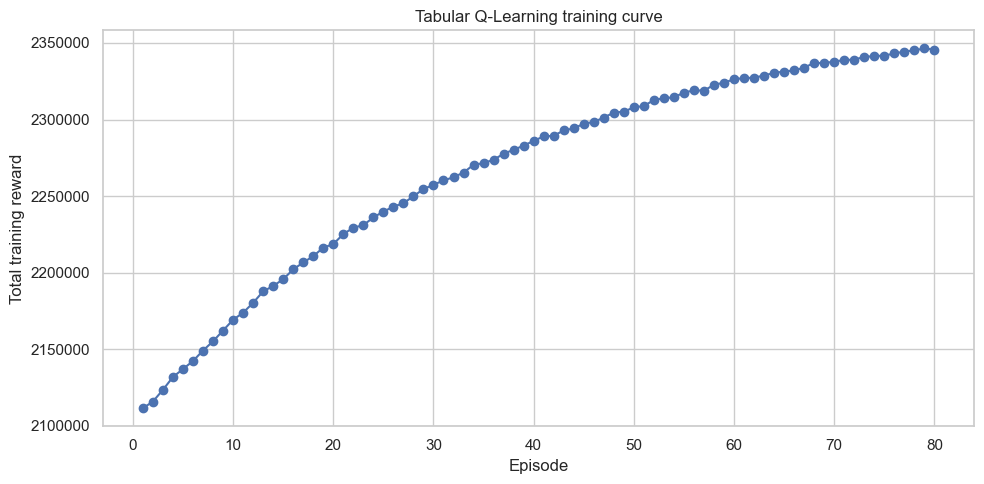

In [47]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(q_agent.history_) + 1), q_agent.history_, marker="o")
plt.xlabel("Episode")
plt.ylabel("Total training reward")
plt.title("Tabular Q-Learning training curve")
ax = plt.gca()
ax.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q_learning_training_curve.png", bbox_inches="tight")
plt.show()


## SARSA

SARSA is an **on-policy** temporal-difference control algorithm.

Unlike Q-learning, which updates toward the best next action value, SARSA updates using the **next action actually chosen by the current policy**. This makes it slightly more conservative and often more sensitive to exploration.

For SARSA we use the same discretized state representation as tabular Q-learning:

- hour
- weekday
- cab type
- product name
- route group
- predicted base-price bin
- predicted demand-score bin
- weather bins

The action space is the same discrete set of surge multipliers.  
We include SARSA to compare an **on-policy** tabular RL method against the **off-policy** tabular Q-learning approach.

In [48]:
sarsa_agent = TabularSARSAAgent(
    actions=ACTION_SPACE,
    alpha=0.10,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.97,
    seed=SEED,
)

sarsa_agent.fit(train_df, state_builder, reward_model, episodes=80, show_progress=True)

print("Number of SARSA training episodes:", len(sarsa_agent.history_))
print("Final SARSA episode reward:", sarsa_agent.history_[-1])

Training SARSA:   0%|          | 0/80 [00:00<?, ?it/s]

Number of SARSA training episodes: 80
Final SARSA episode reward: 2367600.20763989


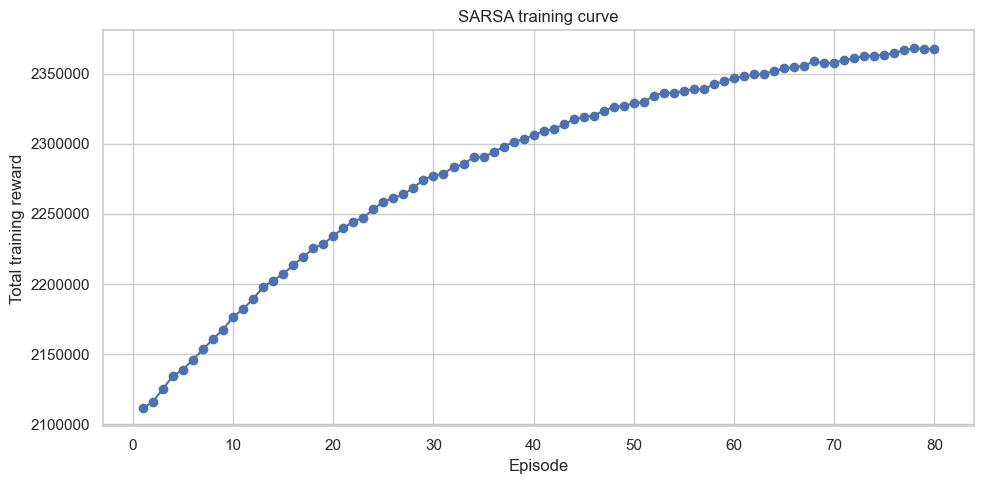

In [49]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(sarsa_agent.history_) + 1), sarsa_agent.history_, marker="o")
plt.xlabel("Episode")
plt.ylabel("Total training reward")
plt.title("SARSA training curve")
ax = plt.gca()
ax.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sarsa_training_curve.png", bbox_inches="tight")
plt.show()



## Thompson Sampling

Thompson Sampling is included here as a **contextual bandit-style benchmark**, rather than a full reinforcement learning method.

Instead of learning long-horizon Bellman updates, it chooses actions by balancing:

- **exploitation** of surge multipliers that have worked well before
- **exploration** of uncertain multipliers

In our implementation, the method is conditioned on the same compact state representation used for the tabular methods:

- hour
- weekday
- cab type
- product name
- route group
- predicted base-price bin
- predicted demand-score bin
- weather bins

For each state-action pair, we maintain running reward statistics.  
At decision time, the algorithm samples from an estimated reward distribution for each action and chooses the action with the highest sampled value.

This gives a useful comparison point because it represents a simpler adaptive pricing strategy that does **not** explicitly model multi-step future rewards.

In [50]:
ts_agent = GaussianThompsonSamplingAgent(
    actions=ACTION_SPACE,
    prior_mean=0.0,
    exploration_scale=1.0,
    seed=SEED,
)

ts_agent.fit(train_df, state_builder, reward_model, episodes=80, show_progress=True)

print("Number of Thompson Sampling passes:", len(ts_agent.history_))
print("Final Thompson Sampling pass reward:", ts_agent.history_[-1])

Training Thompson Sampling:   0%|          | 0/80 [00:00<?, ?it/s]

Number of Thompson Sampling passes: 80
Final Thompson Sampling pass reward: 2118434.141368996


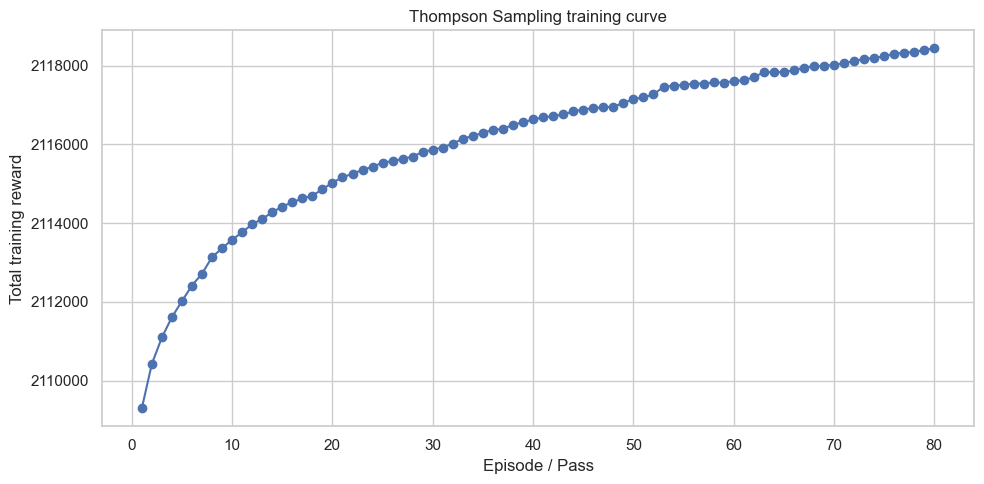

In [51]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(ts_agent.history_) + 1), ts_agent.history_, marker="o")
plt.xlabel("Episode / Pass")
plt.ylabel("Total training reward")
plt.title("Thompson Sampling training curve")
ax = plt.gca()
ax.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "thompson_sampling_training_curve.png", bbox_inches="tight")
plt.show()


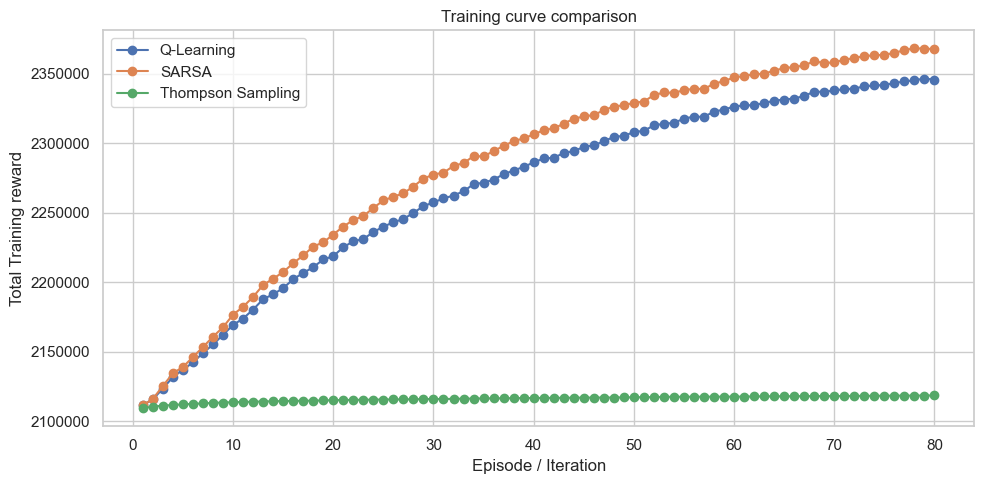

In [52]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(q_agent.history_) + 1), q_agent.history_, marker="o", label="Q-Learning")
plt.plot(np.arange(1, len(sarsa_agent.history_) + 1), sarsa_agent.history_, marker="o", label="SARSA")
plt.plot(np.arange(1, len(ts_agent.history_) + 1), ts_agent.history_, marker="o", label="Thompson Sampling")
plt.xlabel("Episode / Iteration")
plt.ylabel("Total Training reward")
plt.title("Training curve comparison")
plt.legend()
ax = plt.gca()
ax.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curve_comparison.png", bbox_inches="tight")
plt.show()

## 8. Fitted Q-Iteration (FQI)

FQI is a batch RL method.  
It repeatedly fits a regressor to approximate the Q-function using Bellman targets.

Here we use:

- **state features** = contextual variables + supervised model predictions
- **regressor** = Extra Trees
- **action space** = discrete surge multipliers


In [53]:
print(feature_cols)
print(train_df[feature_cols].dtypes)

['source', 'destination', 'cab_type', 'name', 'distance_mean', 'hour', 'weekday', 'is_weekend', 'day', 'month', 'temp', 'clouds', 'pressure', 'rain', 'humidity', 'wind']
source            object
destination       object
cab_type          object
name              object
distance_mean    float64
hour               int32
weekday            int32
is_weekend         int64
day                int32
month              int32
temp             float64
clouds           float64
pressure         float64
rain             float64
humidity         float64
wind             float64
dtype: object


In [54]:
fqi_state_cols = feature_cols + ["pred_base_price", "pred_demand_score"]

fqi_agent = FittedQIterationAgent(
    actions=ACTION_SPACE,
    gamma=0.95,
    n_iterations=5,
    random_state=SEED,
)

fqi_agent.fit(train_df, fqi_state_cols, reward_model, show_progress=True)
print("Fitted Q-Iteration model trained.")

Expanded training shape: (1899678, 19)


Training Fitted Q-Iteration:   0%|          | 0/5 [00:00<?, ?it/s]

Starting FQI iteration 1/5
Starting FQI iteration 2/5
Starting FQI iteration 3/5
Starting FQI iteration 4/5
Starting FQI iteration 5/5
Fitted Q-Iteration model trained.


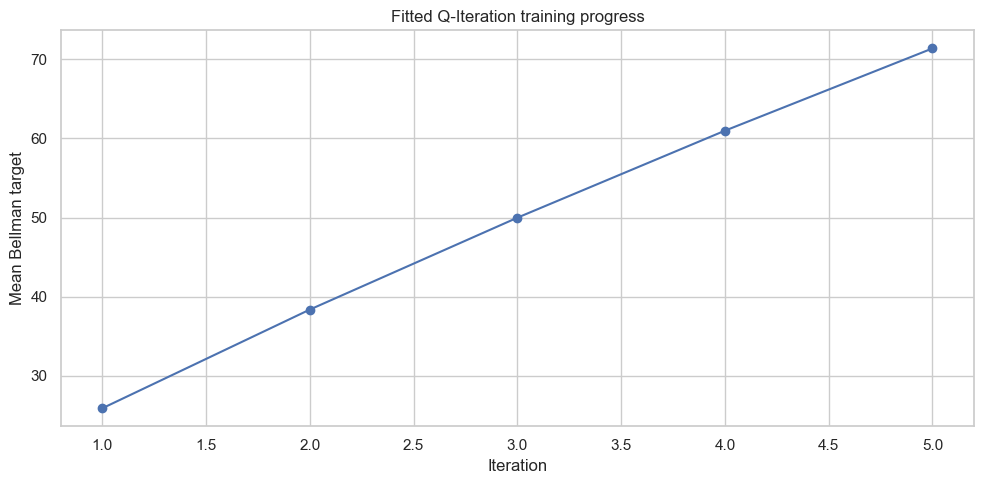

In [55]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(fqi_agent.history_) + 1), fqi_agent.history_, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Mean Bellman target")
plt.title("Fitted Q-Iteration training progress")
ax = plt.gca()
ax.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fqi_training_curve.png", bbox_inches="tight")
plt.show()

## 9. Baselines and policy evaluation

We compare the learned RL policies against simple baselines:

- **No surge**: always 1.0
- **Fixed 1.25x surge**
- **Peak/weather heuristic**: 1.30x during peak hours or bad weather, otherwise 1.0


In [56]:
policy_map = {
    "No Surge": fixed_policy(1.0),
    "Fixed 1.25x": fixed_policy(1.25),
    "Heuristic Peak/Weather": simple_peak_weather_policy,
    "Tabular Q-Learning": lambda row: q_agent.action(row, state_builder),
    "SARSA": lambda row: sarsa_agent.action(row, state_builder),
    "Thompson Sampling": lambda row: ts_agent.action(row, state_builder),
    "Fitted Q-Iteration": lambda row: fqi_agent.action(row),
}

# Check validation performance before test
validation_parts = []
for policy_name, policy_fn in tqdm(policy_map.items(), total=len(policy_map), desc="Validating policies"):
    validation_parts.append(
        evaluate_policy(val_df, policy_name, policy_fn, reward_model)
    )

validation_eval = pd.concat(validation_parts, ignore_index=True)

validation_summary = summarize_policy_results(validation_eval)
display(validation_summary)

validation_summary.to_csv(OUTPUT_DIR / "validation_policy_summary.csv", index=False)


Validating policies:   0%|          | 0/7 [00:00<?, ?it/s]

,policy,total_reward,avg_reward,total_gross_revenue,avg_action,avg_expected_units,n_steps
0,No Surge,516953.717259,13.847840,516953.717259,1.000000,0.848056,37331
1,Fitted Q-Iteration,515199.945899,13.800861,515379.303627,1.018773,0.832239,37331
2,SARSA,507751.291425,13.601331,509318.363413,1.061035,0.802989,37331
3,Tabular Q-Learning,506094.292554,13.556944,507997.001790,1.070933,0.796295,37331
4,Heuristic Peak/Weather,503487.241056,13.487108,505233.766175,1.096073,0.770447,37331
5,Thompson Sampling,492251.418957,13.186130,497373.513790,1.118156,0.768154,37331
6,Fixed 1.25x,484676.145213,12.983208,488464.991711,1.250000,0.640860,37331


In [57]:
# Final evaluation on the held-out test set

test_parts = []

for policy_name, policy_fn in tqdm(policy_map.items(), total=len(policy_map), desc="Testing policies"):
    test_parts.append(
        evaluate_policy(test_df, policy_name, policy_fn, reward_model)
    )

test_eval = pd.concat(test_parts, ignore_index=True)

test_summary = summarize_policy_results(test_eval)
display(test_summary)

test_eval.to_csv(OUTPUT_DIR / "test_policy_step_results.csv", index=False)
test_summary.to_csv(OUTPUT_DIR / "test_policy_summary.csv", index=False)


Testing policies:   0%|          | 0/7 [00:00<?, ?it/s]

,policy,total_reward,avg_reward,total_gross_revenue,avg_action,avg_expected_units,n_steps
0,No Surge,517357.619514,13.997771,517357.619514,1.000000,0.855649,36960
1,Fitted Q-Iteration,515514.828981,13.947912,515706.866130,1.019881,0.838895,36960
2,SARSA,513478.378044,13.892813,514164.417883,1.025647,0.836944,36960
3,Tabular Q-Learning,513077.748490,13.881974,513846.627062,1.026223,0.836415,36960
4,Thompson Sampling,507822.919606,13.739798,509848.359134,1.042779,0.826786,36960
5,Heuristic Peak/Weather,493588.318701,13.354662,496671.734578,1.170446,0.716548,36960
6,Fixed 1.25x,485360.904177,13.132059,489124.522932,1.250000,0.647033,36960


In [58]:
# Report-friendly improvement table relative to the "No Surge" baseline

baseline_reward = float(
    test_summary.loc[test_summary["policy"] == "No Surge", "total_reward"].iloc[0]
)

comparison_df = test_summary.copy()
comparison_df["absolute_improvement_vs_no_surge"] = comparison_df["total_reward"] - baseline_reward
comparison_df["pct_improvement_vs_no_surge"] = 100 * comparison_df["absolute_improvement_vs_no_surge"] / baseline_reward

display(comparison_df)
comparison_df.to_csv(OUTPUT_DIR / "test_policy_comparison_vs_no_surge.csv", index=False)


,policy,total_reward,avg_reward,total_gross_revenue,avg_action,avg_expected_units,n_steps,absolute_improvement_vs_no_surge,pct_improvement_vs_no_surge
0,No Surge,517357.619514,13.997771,517357.619514,1.000000,0.855649,36960,0.000000,0.000000
1,Fitted Q-Iteration,515514.828981,13.947912,515706.866130,1.019881,0.838895,36960,-1842.790534,-0.356193
2,SARSA,513478.378044,13.892813,514164.417883,1.025647,0.836944,36960,-3879.241470,-0.749818
3,Tabular Q-Learning,513077.748490,13.881974,513846.627062,1.026223,0.836415,36960,-4279.871025,-0.827256
4,Thompson Sampling,507822.919606,13.739798,509848.359134,1.042779,0.826786,36960,-9534.699908,-1.842961
5,Heuristic Peak/Weather,493588.318701,13.354662,496671.734578,1.170446,0.716548,36960,-23769.300813,-4.594366
6,Fixed 1.25x,485360.904177,13.132059,489124.522932,1.250000,0.647033,36960,-31996.715338,-6.184642


## 10. Visualisations of policy performance


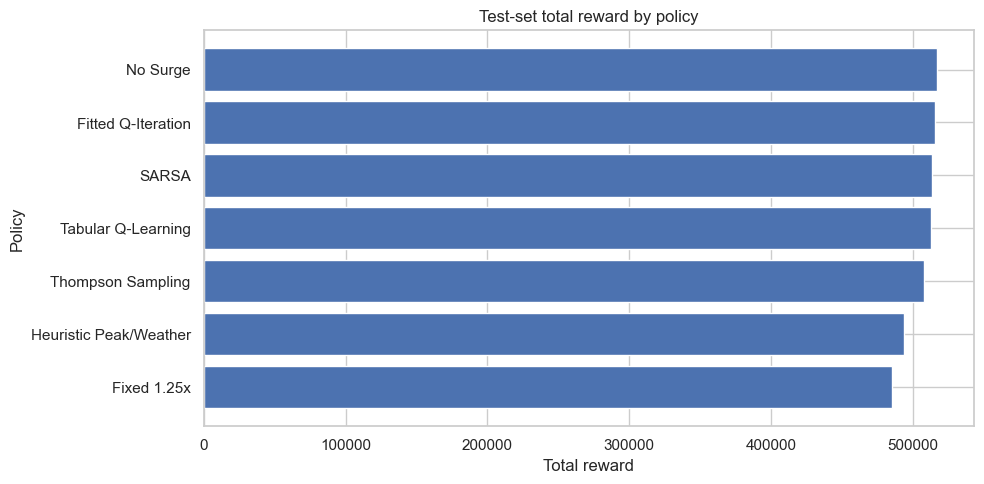

In [59]:
# Total reward by policy

ordered = test_summary.sort_values("total_reward", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(ordered["policy"], ordered["total_reward"])
plt.xlabel("Total reward")
plt.ylabel("Policy")
plt.title("Test-set total reward by policy")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_total_reward_by_policy.png", bbox_inches="tight")
plt.show()


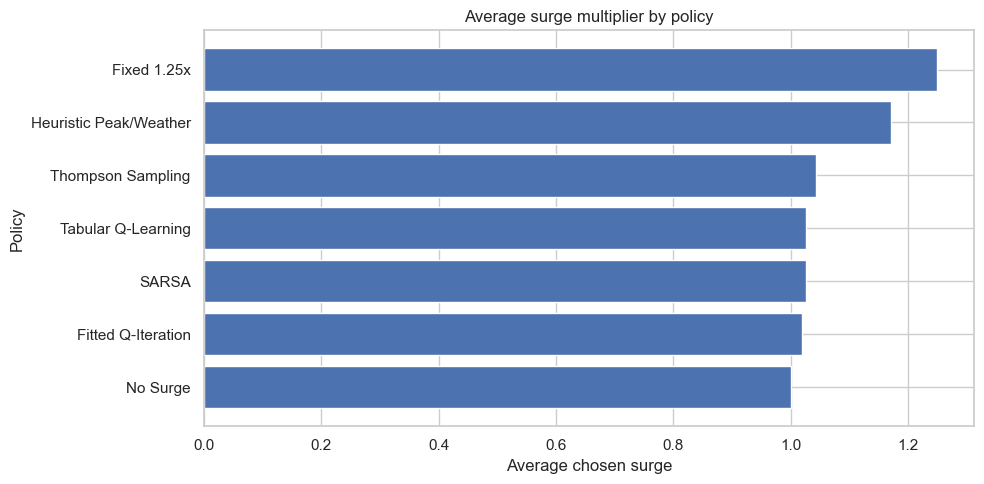

In [60]:
# Average chosen surge by policy

ordered = test_summary.sort_values("avg_action", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(ordered["policy"], ordered["avg_action"])
plt.xlabel("Average chosen surge")
plt.ylabel("Policy")
plt.title("Average surge multiplier by policy")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "average_action_by_policy.png", bbox_inches="tight")
plt.show()


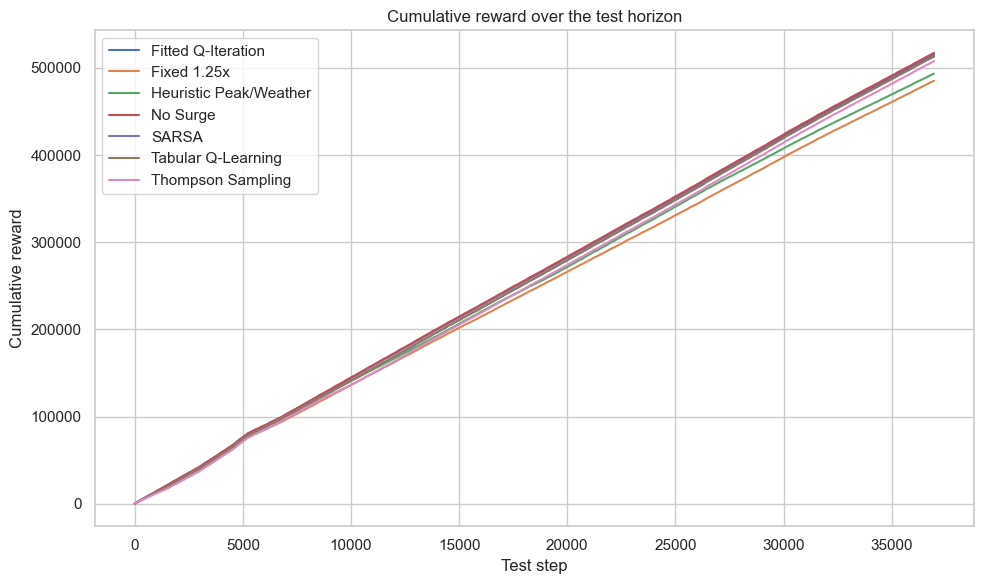

In [61]:
# Cumulative reward trajectory on the test set

plot_df = test_eval.copy()
plot_df["step"] = plot_df.groupby("policy").cumcount()
plot_df["cumulative_reward"] = plot_df.groupby("policy")["reward"].cumsum()

plt.figure(figsize=(10, 6))
for policy_name, group in plot_df.groupby("policy"):
    plt.plot(group["step"], group["cumulative_reward"], label=policy_name)

plt.xlabel("Test step")
plt.ylabel("Cumulative reward")
plt.title("Cumulative reward over the test horizon")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cumulative_reward_over_test_horizon.png", bbox_inches="tight")
plt.show()


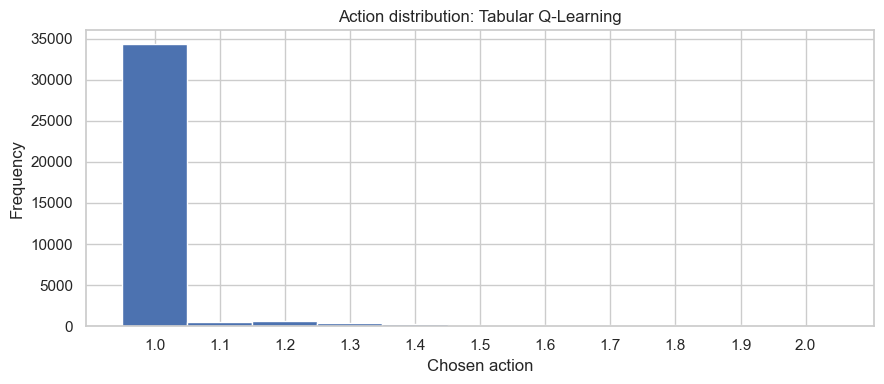

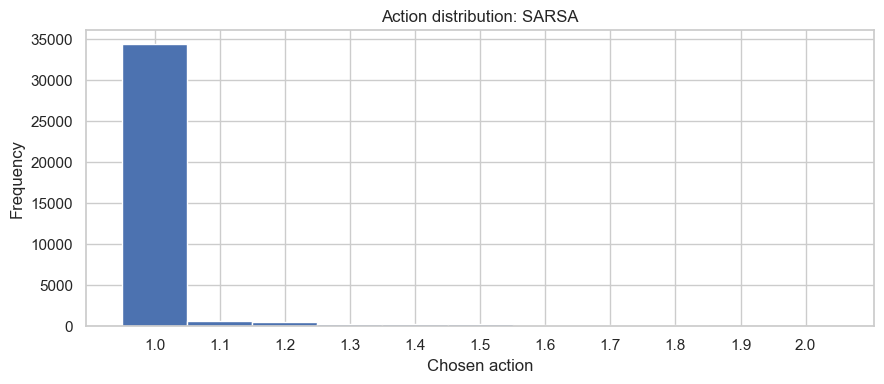

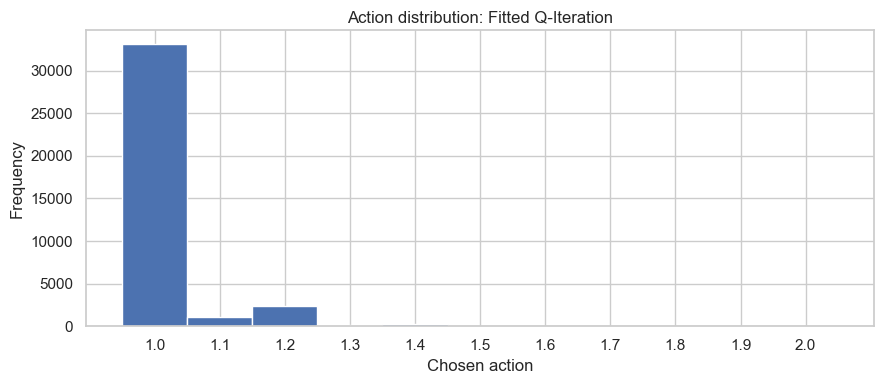

In [62]:
# Action distribution for the two learned policies

learned_eval = test_eval[test_eval["policy"].isin(["Tabular Q-Learning", "Fitted Q-Iteration", "SARSA"])]

for policy_name in learned_eval["policy"].unique():
    policy_data = learned_eval.loc[learned_eval["policy"] == policy_name, "action"]
    plt.figure(figsize=(9, 4))
    bins = np.append(ACTION_SPACE - 0.05, ACTION_SPACE[-1] + 0.05)
    plt.hist(policy_data, bins=bins)
    plt.xticks(ACTION_SPACE)
    plt.xlabel("Chosen action")
    plt.ylabel("Frequency")
    plt.title(f"Action distribution: {policy_name}")
    plt.tight_layout()
    file_name = f"action_distribution_{policy_name.lower().replace(' ', '_').replace('/', '_')}.png"
    plt.savefig(OUTPUT_DIR / file_name, bbox_inches="tight")
    plt.show()


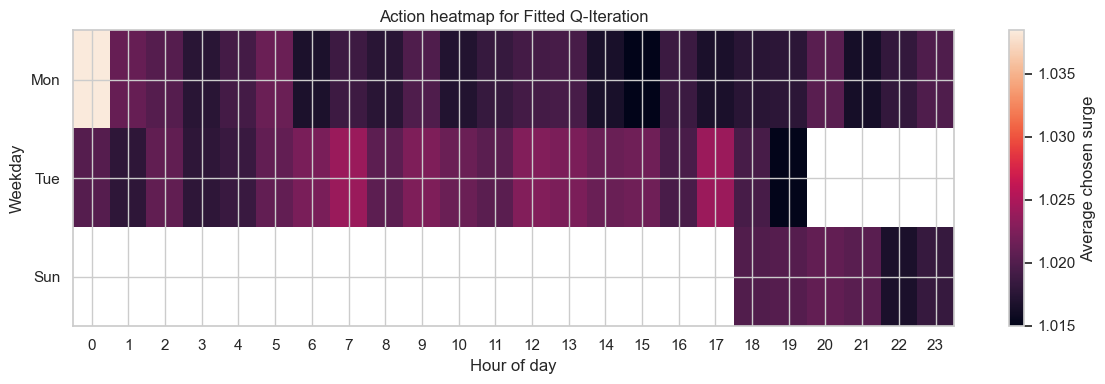

In [63]:
# Heatmap: average action by weekday and hour for the best-performing learned policy

best_learned_policy = test_summary[
    test_summary["policy"].isin(["Tabular Q-Learning", "Fitted Q-Iteration", "SARSA"])
].sort_values("total_reward", ascending=False)["policy"].iloc[0]

heatmap_df = (
    test_eval[test_eval["policy"] == best_learned_policy]
    .pivot_table(index="weekday", columns="hour", values="action", aggfunc="mean")
    .sort_index()
)

weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(12, 4))
plt.imshow(heatmap_df, aspect="auto")
plt.colorbar(label="Average chosen surge")
plt.yticks(range(len(heatmap_df.index)), [weekday_labels[i] for i in heatmap_df.index])
plt.xticks(range(len(heatmap_df.columns)), heatmap_df.columns)
plt.xlabel("Hour of day")
plt.ylabel("Weekday")
plt.title(f"Action heatmap for {best_learned_policy}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "best_policy_action_heatmap.png", bbox_inches="tight")
plt.show()


,route,avg_action,avg_reward,n
26,Financial District -> Haymarket Square,1.056335,11.284320,513
27,Financial District -> North End,1.055714,11.178572,490
1,Back Bay -> Fenway,1.046004,11.530667,513
41,North End -> West End,1.045562,11.179233,507
42,North Station -> Boston University,1.043100,15.721789,529
38,North End -> Financial District,1.040385,10.932430,520
0,Back Bay -> Boston University,1.038310,12.200525,509
65,Theatre District -> South Station,1.038104,11.069165,517
56,South Station -> Financial District,1.037864,10.617172,515
35,Haymarket Square -> West End,1.037232,9.961898,513


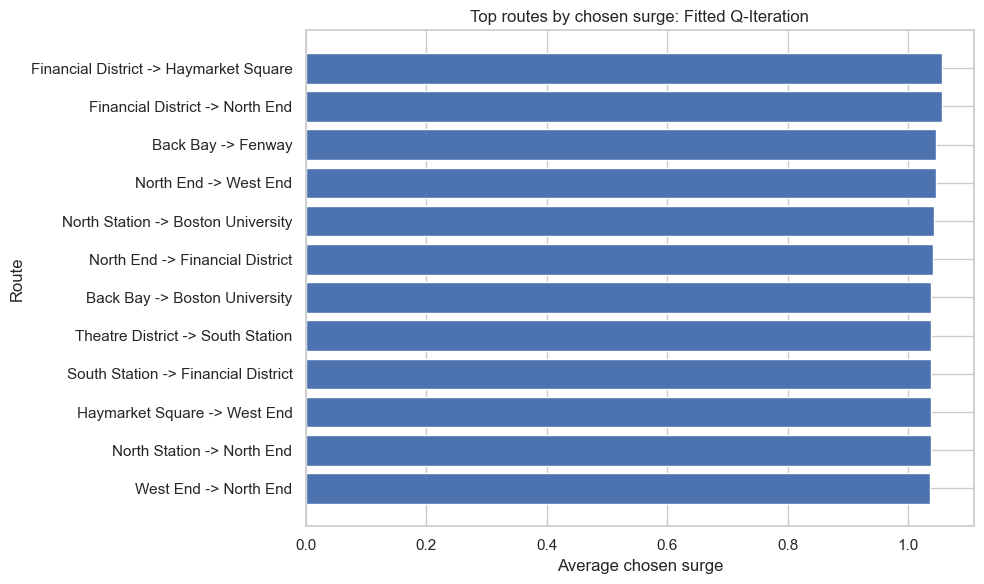

In [64]:
# Route-level analysis for the best learned policy

route_analysis = (
    test_eval[test_eval["policy"] == best_learned_policy]
    .groupby("route", as_index=False)
    .agg(
        avg_action=("action", "mean"),
        avg_reward=("reward", "mean"),
        n=("route", "size")
    )
    .sort_values("avg_action", ascending=False)
)

display(route_analysis.head(15))

top_route_plot = route_analysis.head(12).sort_values("avg_action", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_route_plot["route"], top_route_plot["avg_action"])
plt.xlabel("Average chosen surge")
plt.ylabel("Route")
plt.title(f"Top routes by chosen surge: {best_learned_policy}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_routes_by_best_policy_action.png", bbox_inches="tight")
plt.show()


## 11. Export everything needed for the report

The following files should now exist inside `./outputs/`:

- processed context dataset
- supervised model metrics
- validation/test policy summaries
- detailed step-level test results
- comparison table vs no-surge baseline
- figures as `.png`


In [65]:
print("Files written to outputs directory:")
for file_path in sorted(OUTPUT_DIR.glob("*")):
    print("-", file_path.name)


Files written to outputs directory:
- action_distribution_fitted_q-iteration.png
- action_distribution_sarsa.png
- action_distribution_tabular_q-learning.png
- average_action_by_policy.png
- best_policy_action_heatmap.png
- context_table.csv
- cumulative_reward_over_test_horizon.png
- fqi_training_curve.png
- historical_price_surge_by_hour.png
- historical_surge_by_hour.png
- price_distribution.png
- q_learning_training_curve.png
- reward_vs_action.png
- sarsa_training_curve.png
- supervised_model_diagnostics.png
- supervised_model_metrics.csv
- surge_multiplier_distribution.png
- test_policy_comparison_vs_no_surge.csv
- test_policy_step_results.csv
- test_policy_summary.csv
- test_total_reward_by_policy.png
- thompson_sampling_training_curve.png
- top_routes_by_best_policy_action.png
- top_routes_by_historical_surge.png
- training_curve_comparison.png
- validation_policy_summary.csv
